PRACTICAL 4: PROMPT ENGINEERING AND RAG

----------------------------------------------------------------------
1. PROMPT ENGINEERING
----------------------------------------------------------------------

Weak prompt:
Explain AI.

Clear structured prompt:
You are a computer science tutor.
Explain Generative AI to a B.Tech CSE student.
Use exactly 4 bullet points.
Keep each point short and include one simple example.

Few-shot prompt:
Task: classify the following sentence as Positive or Negative.

Example 1:
Sentence: The application is fast and easy to use.
Label: Positive

Example 2:
Sentence: The application crashes frequently.
Label: Negative

New sentence:
The application has a simple interface and works smoothly.
Label:

Prompt engineering principles demonstrated:
• Clear role and task
• Specific output format
• Constraints on length
• Examples for few-shot prompting

----------------------------------------------------------------------
2. BUILDING THE RAG RETRIEVER
------------

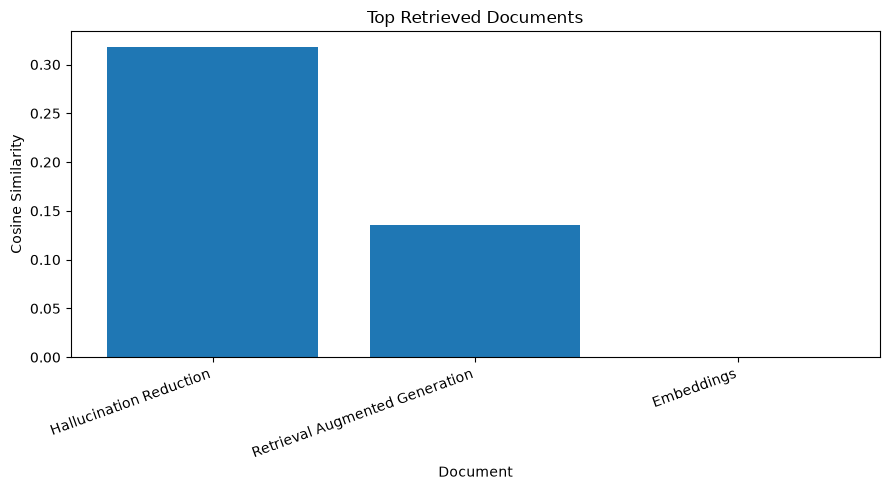


----------------------------------------------------------------------
3. GROUNDED RAG ANSWER
----------------------------------------------------------------------
Grounded answer:
Grounding an answer in retrieved evidence can reduce unsupported claims. A RAG system should refuse to answer when the available evidence is insufficient. Retrieval Augmented Generation, or RAG, retrieves relevant information from an external knowledge source and supplies that information as context to a generative model.

Sources: Hallucination Reduction, Retrieval Augmented Generation

----------------------------------------------------------------------
4. HALLUCINATION CONTROL TEST
----------------------------------------------------------------------
Query: Who invented quantum computing in the year 1890?

Response:
I cannot answer this question from the available knowledge base because sufficient evidence was not found.

RAG PIPELINE

User Query
    |
    v
TF-IDF Vectorization
    |
    v
Cosine Si

In [4]:
import re
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


print("=" * 70)
print("PRACTICAL 4: PROMPT ENGINEERING AND RAG")
print("=" * 70)

# ----------------------------------------------------------------
# 1. Prompt Engineering Examples
# ----------------------------------------------------------------
print("\n" + "-" * 70)
print("1. PROMPT ENGINEERING")
print("-" * 70)

weak_prompt = "Explain AI."

clear_prompt = """
You are a computer science tutor.
Explain Generative AI to a B.Tech CSE student.
Use exactly 4 bullet points.
Keep each point short and include one simple example.
"""

few_shot_prompt = """
Task: classify the following sentence as Positive or Negative.

Example 1:
Sentence: The application is fast and easy to use.
Label: Positive

Example 2:
Sentence: The application crashes frequently.
Label: Negative

New sentence:
The application has a simple interface and works smoothly.
Label:
"""

print("\nWeak prompt:")
print(weak_prompt)

print("\nClear structured prompt:")
print(clear_prompt.strip())

print("\nFew-shot prompt:")
print(few_shot_prompt.strip())

print("\nPrompt engineering principles demonstrated:")
print("• Clear role and task")
print("• Specific output format")
print("• Constraints on length")
print("• Examples for few-shot prompting")

# ----------------------------------------------------------------
# 2. Knowledge Base for RAG
# ----------------------------------------------------------------
documents = [
    {
        "title": "Generative AI",
        "text": (
            "Generative AI is a branch of artificial intelligence "
            "that learns patterns from data and generates new content "
            "such as text, images, audio, video, or code."
        )
    },
    {
        "title": "Large Language Model",
        "text": (
            "A large language model is trained on large collections "
            "of text and predicts tokens to produce natural-language "
            "sequences."
        )
    },
    {
        "title": "Prompt Engineering",
        "text": (
            "Prompt engineering is the process of designing and "
            "refining instructions and context supplied to a generative "
            "model to obtain useful and consistent responses."
        )
    },
    {
        "title": "Retrieval Augmented Generation",
        "text": (
            "Retrieval Augmented Generation, or RAG, retrieves relevant "
            "information from an external knowledge source and supplies "
            "that information as context to a generative model."
        )
    },
    {
        "title": "Hallucination Reduction",
        "text": (
            "Grounding an answer in retrieved evidence can reduce "
            "unsupported claims. A RAG system should refuse to answer "
            "when the available evidence is insufficient."
        )
    },
    {
        "title": "Transformer",
        "text": (
            "A Transformer is a neural network architecture that uses "
            "attention mechanisms to model relationships between tokens."
        )
    },
    {
        "title": "Embeddings",
        "text": (
            "Embeddings are numerical vector representations of text "
            "that can be compared to estimate semantic or lexical "
            "similarity."
        )
    }
]

corpus = [doc["text"] for doc in documents]

# ----------------------------------------------------------------
# 3. Build Retriever
# ----------------------------------------------------------------
print("\n" + "-" * 70)
print("2. BUILDING THE RAG RETRIEVER")
print("-" * 70)

vectorizer = TfidfVectorizer(stop_words="english")
document_vectors = vectorizer.fit_transform(corpus)

print("Knowledge-base documents:", len(documents))
print("TF-IDF matrix shape:", document_vectors.shape)

# ----------------------------------------------------------------
# 4. Retrieval Function
# ----------------------------------------------------------------
def retrieve(query, top_k=3):
    """Return the top-k documents ranked by cosine similarity."""
    query_vector = vectorizer.transform([query])
    scores = cosine_similarity(query_vector, document_vectors)[0]

    ranked_indices = np.argsort(scores)[::-1][:top_k]

    results = []
    for index in ranked_indices:
        results.append({
            "title": documents[index]["title"],
            "text": documents[index]["text"],
            "score": float(scores[index])
        })

    return results


query = "How does RAG help reduce hallucinations?"

results = retrieve(query, top_k=3)

print("\nQuery:", query)
print("\nRetrieved documents:")

for rank, item in enumerate(results, start=1):
    print(f"\nRank {rank}: {item['title']}")
    print(f"Similarity score: {item['score']:.4f}")
    print("Text:", item["text"])

# ----------------------------------------------------------------
# 5. Visualize Retrieval Scores
# ----------------------------------------------------------------
titles = [item["title"] for item in results]
scores = [item["score"] for item in results]

plt.figure(figsize=(9, 5))
plt.bar(titles, scores)
plt.title("Top Retrieved Documents")
plt.xlabel("Document")
plt.ylabel("Cosine Similarity")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

# ----------------------------------------------------------------
# 6. Grounded RAG Answer Generator
# ----------------------------------------------------------------
def grounded_answer(query, top_k=3, threshold=0.10):
    """
    Lightweight generation stage.

    The response is created only from retrieved evidence. If the
    retrieval score is too low, the system refuses to invent an
    answer. This demonstrates the grounding principle of RAG.
    """
    results = retrieve(query, top_k=top_k)

    useful = [item for item in results if item["score"] >= threshold]

    if not useful:
        return (
            "I cannot answer this question from the available "
            "knowledge base because sufficient evidence was not found."
        ), results

    evidence = " ".join(item["text"] for item in useful)

    answer = (
        "Grounded answer:\n"
        + evidence
        + "\n\nSources: "
        + ", ".join(item["title"] for item in useful)
    )

    return answer, results


answer, _ = grounded_answer(
    "How does RAG help reduce hallucinations?"
)

print("\n" + "-" * 70)
print("3. GROUNDED RAG ANSWER")
print("-" * 70)
print(answer)

# ----------------------------------------------------------------
# 7. Hallucination-Control Test
# ----------------------------------------------------------------
unknown_query = "Who invented quantum computing in the year 1890?"

unknown_answer, unknown_results = grounded_answer(
    unknown_query,
    top_k=3,
    threshold=0.25
)

print("\n" + "-" * 70)
print("4. HALLUCINATION CONTROL TEST")
print("-" * 70)
print("Query:", unknown_query)
print("\nResponse:")
print(unknown_answer)

# ----------------------------------------------------------------
# 8. RAG Pipeline Summary
# ----------------------------------------------------------------
print("\n" + "=" * 70)
print("RAG PIPELINE")
print("=" * 70)
print("""
User Query
    |
    v
TF-IDF Vectorization
    |
    v
Cosine Similarity Retrieval
    |
    v
Top-K Relevant Documents
    |
    v
Grounded Prompt / Context
    |
    v
Evidence-based Answer
    |
    v
If evidence is insufficient -> Refuse instead of inventing facts
""")

print("=" * 70)
print("OBSERVATION")
print("=" * 70)
print("1. Clear prompts provide better task instructions and constraints.")
print("2. Few-shot prompts provide examples of the expected behavior.")
print("3. TF-IDF retrieval identifies relevant knowledge-base documents.")
print("4. Retrieved evidence is used as context for a grounded answer.")
print("5. A confidence threshold prevents unsupported answers when")
print("   relevant evidence is not available.")

print("\n" + "=" * 70)
print("CONCLUSION")
print("=" * 70)
print("Prompt engineering improves the clarity and consistency of")
print("generative-AI instructions. RAG grounds responses in retrieved")
print("information and can reduce hallucination by requiring evidence")
print("from an external knowledge source.")
print("=" * 70)